In [ ]:
# ============================================================
# INSTALLS, IMPORTS, SEEDING, MOUNT GOOGLE DRIVE
# ============================================================

!pip install -q scikit-learn
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, regularizers

from sklearn.metrics import confusion_matrix, classification_report
from sklearn.utils.class_weight import compute_class_weight
import itertools

# Reproducibility
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# ============================================================
# PATHS & CLASS LIST
# ============================================================

BASE_DIR = '/content/drive/MyDrive/brain_tumor_mris'
train_dir = BASE_DIR + '/Training'
val_dir   = BASE_DIR + '/Validation'
test_dir  = BASE_DIR + '/Testing'

print("Train dir:", train_dir)
print("Val dir: ", val_dir)
print("Test dir:", test_dir)

# Classes (from Training folder)
classes = sorted([
    d for d in tf.io.gfile.listdir(train_dir)
    if not d.startswith('.')
])
print("Classes:", classes)
num_classes = len(classes)

# Common image extensions
extensions = ('.png', '.jpg', '.jpeg', '.bmp', '.tif', '.tiff')

Train dir: /content/drive/MyDrive/brain_tumor_mris1/Training
Val dir:  /content/drive/MyDrive/brain_tumor_mris1/Validation
Test dir: /content/drive/MyDrive/brain_tumor_mris1/Testing
Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']


Training counts: {'glioma': 1168, 'meningioma': 1168, 'notumor': 1168, 'pituitary': 1168}
Validation counts: {'glioma': 144, 'meningioma': 144, 'notumor': 144, 'pituitary': 144}
Testing counts: {'glioma': 144, 'meningioma': 144, 'notumor': 144, 'pituitary': 144}

Total images in Training: 4672
Total images in Validation: 576
Total images in Testing: 576


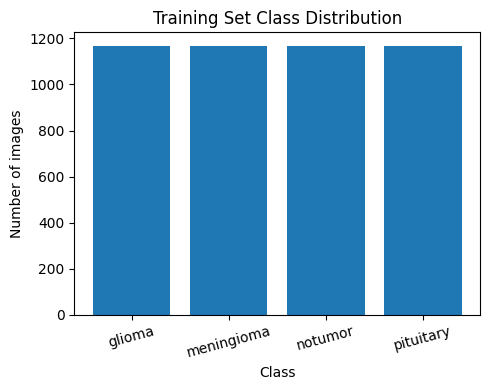

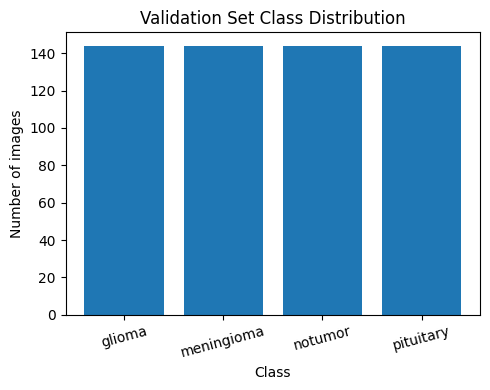

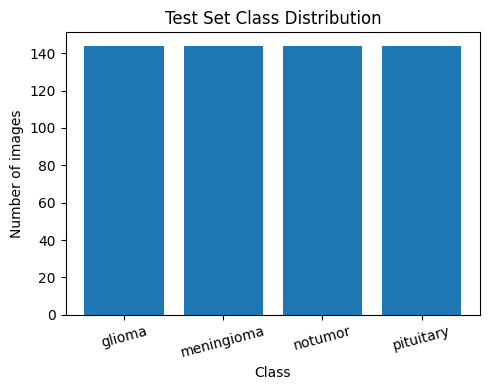

In [ ]:
# ============================================================
# DATA UNDERSTANDING: COUNTS & CLASS DISTRIBUTION
# ============================================================

def count_images_in_split(directory, classes):
    counts = {}
    for cls in classes:
        class_dir = directory + '/' + cls
        if not tf.io.gfile.isdir(class_dir):
            counts[cls] = 0
            continue
        files = tf.io.gfile.listdir(class_dir)
        n = sum(f.lower().endswith(extensions) for f in files)
        counts[cls] = n
    return counts

train_counts = count_images_in_split(train_dir, classes)
val_counts   = count_images_in_split(val_dir, classes)
test_counts  = count_images_in_split(test_dir, classes)

print("Training counts:", train_counts)
print("Validation counts:", val_counts)
print("Testing counts:", test_counts)
print("\nTotal images in Training:",   sum(train_counts.values()))
print("Total images in Validation:",  sum(val_counts.values()))
print("Total images in Testing:",     sum(test_counts.values()))

def plot_class_distribution(counts, title):
    labels = list(counts.keys())
    values = list(counts.values())
    plt.figure(figsize=(5,4))
    plt.bar(labels, values)
    plt.title(title)
    plt.xlabel("Class")
    plt.ylabel("Number of images")
    plt.xticks(rotation=15)
    plt.tight_layout()
    plt.show()

plot_class_distribution(train_counts, "Training Set Class Distribution")
plot_class_distribution(val_counts,   "Validation Set Class Distribution")
plot_class_distribution(test_counts,  "Test Set Class Distribution")

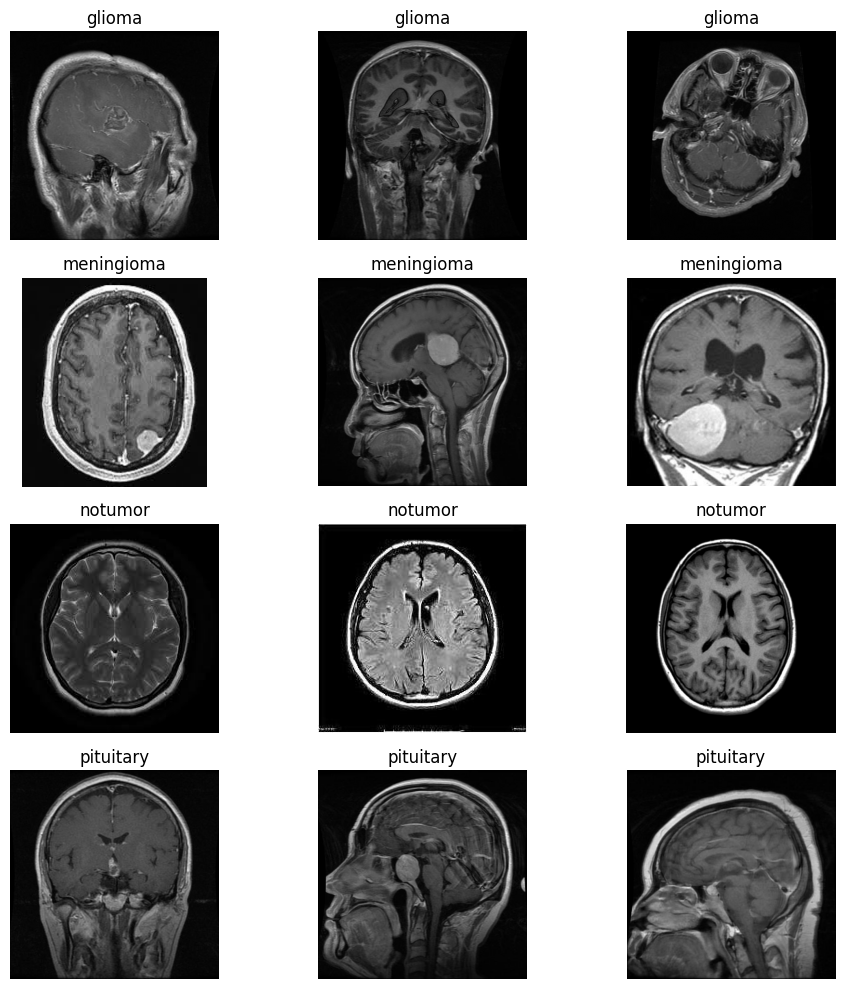

In [ ]:
# ============================================================
# DATA UNDERSTANDING: SAMPLE IMAGES
# ============================================================

def show_sample_images(split_dir, n_per_class=3):
    plt.figure(figsize=(12, 12))
    idx = 1
    for cls in classes:
        class_dir = split_dir + '/' + cls
        if not tf.io.gfile.isdir(class_dir):
            continue
        images = [
            f for f in tf.io.gfile.listdir(class_dir)
            if f.lower().endswith(extensions)
        ]
        if len(images) == 0:
            continue

        indices = np.arange(len(images))
        if len(indices) > n_per_class:
            chosen_idx = np.random.choice(indices, size=n_per_class, replace=False)
        else:
            chosen_idx = indices

        for i_idx in chosen_idx:
            img_path = class_dir + '/' + images[i_idx]
            img = keras.preprocessing.image.load_img(img_path, color_mode='grayscale')
            plt.subplot(len(classes), n_per_class, idx)
            plt.imshow(img, cmap='gray')
            plt.title(cls)
            plt.axis('off')
            idx += 1
    plt.tight_layout()
    plt.show()

show_sample_images(train_dir, n_per_class=3)

In [ ]:
# ============================================================
# DATA CLEANING: CORRUPTED IMAGES, SHAPES & MODES, DUPLICATES
# ============================================================

splits = ['Training', 'Validation', 'Testing']

# ---------- (a) Find corrupted / unreadable images ----------

bad_images = []

def is_image_valid_tf(path):
    try:
        img_bytes = tf.io.read_file(path)
        _ = tf.image.decode_image(img_bytes, channels=0)  # keep original channels
        return True
    except Exception as e:
        print(f"Corrupted or unreadable image: {path} ({e})")
        return False

for split in splits:
    for cls in classes:
        folder = BASE_DIR + '/' + split + '/' + cls
        if not tf.io.gfile.isdir(folder):
            continue
        for fname in tf.io.gfile.listdir(folder):
            if fname.lower().endswith(extensions):
                fpath = folder + '/' + fname
                if not is_image_valid_tf(fpath):
                    bad_images.append(fpath)

print("\nTotal corrupted/unreadable images found:", len(bad_images))


Total corrupted/unreadable images found: 0


In [ ]:
# ---------- (b) Check image shapes (H, W, C) AND modes ----------

shape_counts = {}
mode_counts  = {}

for split in splits:
    for cls in classes:
        folder = BASE_DIR + '/' + split + '/' + cls
        if not tf.io.gfile.isdir(folder):
            continue

        for fname in tf.io.gfile.listdir(folder):
            if not fname.lower().endswith(extensions):
                continue

            fpath = folder + '/' + fname
            try:
                img_bytes = tf.io.read_file(fpath)
                img = tf.image.decode_image(img_bytes, channels=0)  # keep original channels
                arr = img.numpy()
                shape = tuple(arr.shape)  # (H,W) or (H,W,C)

                # Count shape
                shape_counts[shape] = shape_counts.get(shape, 0) + 1

                # Infer approximate mode from channels
                if len(shape) == 2:
                    mode = "grayscale"
                elif len(shape) == 3:
                    c = shape[2]
                    if c == 1:
                        mode = "grayscale"
                    elif c == 3:
                        mode = "RGB"
                    elif c == 4:
                        mode = "RGBA"
                    else:
                        mode = f"{c}-channel"
                else:
                    mode = "unknown"

                mode_counts[mode] = mode_counts.get(mode, 0) + 1

            except Exception as e:
                # print("Error reading", fpath, "->", e)
                continue

print("\nMost common image shapes:")
for shape, cnt in sorted(shape_counts.items(), key=lambda x: x[1], reverse=True)[:10]:
    print(shape, ":", cnt)

print("\nImage modes (approx):")
for mode, cnt in sorted(mode_counts.items(), key=lambda x: x[1], reverse=True):
    print(mode, ":", cnt)


Most common image shapes:
(512, 512, 1) : 2460
(512, 512, 3) : 1640
(225, 225, 3) : 225
(236, 236, 3) : 78
(630, 630, 3) : 53
(251, 201, 3) : 41
(442, 442, 3) : 35
(168, 300, 3) : 32
(221, 228, 3) : 31
(417, 428, 3) : 30

Image modes (approx):
RGB : 3333
grayscale : 2488
RGBA : 3


In [ ]:
# ---------- (c) Approximate duplicate images using TF + NumPy ----------
# Remove duplicates ONLY from Training + Validation; keep TEST as is.
# ============================================================

def simple_image_hash(path, target_size=(64, 64)):
    """
    Load image with TensorFlow, resize to a small fixed size,
    convert to uint8 NumPy array, then hash the raw bytes.
    Images with the same content will (very likely) have the same hash.
    """
    img_bytes = tf.io.read_file(path)
    # use 3 channels for hashing consistency
    img = tf.image.decode_image(img_bytes, channels=3)
    img = tf.image.resize(img, target_size)
    img = tf.cast(img, tf.uint8).numpy()
    return hash(img.tobytes())

hash_to_files = {}

for split in splits:
    for cls in classes:
        folder = BASE_DIR + '/' + split + '/' + cls
        if not tf.io.gfile.isdir(folder):
            continue
        for fname in tf.io.gfile.listdir(folder):
            if fname.lower().endswith(extensions):
                fpath = folder + '/' + fname
                try:
                    h = simple_image_hash(fpath)
                    if h not in hash_to_files:
                        hash_to_files[h] = [fpath]
                    else:
                        hash_to_files[h].append(fpath)
                except Exception as e:
                    print("Error hashing image:", fpath, "->", e)

duplicate_groups = [paths for paths in hash_to_files.values() if len(paths) > 1]

print("\nNumber of approximate duplicate groups (current state):", len(duplicate_groups))
for i, group in enumerate(duplicate_groups[:5], start=1):
    print(f"\nExample duplicate group {i}:")
    for p in group:
        print(" ", p)


Number of exact duplicate groups (current state): 182

Example duplicate group 1:
   /content/drive/MyDrive/brain_tumor_mris/Training/meningioma/Tr-me_0211.jpg
   /content/drive/MyDrive/brain_tumor_mris/Training/meningioma/Tr-me_0366.jpg
   /content/drive/MyDrive/brain_tumor_mris/Training/meningioma/Tr-me_0176.jpg

Example duplicate group 2:
   /content/drive/MyDrive/brain_tumor_mris/Training/meningioma/Tr-me_0251.jpg
   /content/drive/MyDrive/brain_tumor_mris/Training/meningioma/Tr-me_0249.jpg

Example duplicate group 3:
   /content/drive/MyDrive/brain_tumor_mris/Training/meningioma/Tr-me_0616.jpg
   /content/drive/MyDrive/brain_tumor_mris/Training/meningioma/Tr-me_0617.jpg

Example duplicate group 4:
   /content/drive/MyDrive/brain_tumor_mris/Training/meningioma/Tr-me_0238.jpg
   /content/drive/MyDrive/brain_tumor_mris/Training/meningioma/Tr-me_0227.jpg

Example duplicate group 5:
   /content/drive/MyDrive/brain_tumor_mris/Training/meningioma/Tr-me_0283.jpg
   /content/drive/MyDrive

In [ ]:
# Build a pandas DataFrame for duplicate summary
dup_rows = []
for h, paths in hash_to_files.items():
    if len(paths) > 1:
        for p in paths:
            parts = p.split('/')
            split_name = parts[-3]
            class_name = parts[-2]
            dup_rows.append({
                'hash': h,
                'split': split_name,
                'class': class_name,
                'path': p
            })

if len(dup_rows) > 0:
    dup_df = pd.DataFrame(dup_rows)
    print("\nDuplicate summary (first 10 rows):")
    print(dup_df.head(10))

    print("\nDuplicate counts per (split, class):")
    print(dup_df.groupby(['split', 'class']).size())
else:
    print("\nNo duplicates detected by simple_image_hash.")


Duplicate files per (Split, Class):
  Testing     glioma     : 2
  Testing     meningioma : 6
  Testing     notumor    : 87
  Testing     pituitary  : 4
  Training    meningioma : 13
  Training    notumor    : 321
  Training    pituitary  : 26
  Validation  notumor    : 5


In [ ]:
# -------- PLAN: REMOVE DUPLICATES ONLY FROM TRAIN + VAL (KEEP TEST) --------

files_to_delete = []

for group in duplicate_groups:
    train_files = []
    val_files   = []
    test_files  = []

    for p in group:
        if '/Training/' in p:
            train_files.append(p)
        elif '/Validation/' in p:
            val_files.append(p)
        elif '/Testing/' in p:
            test_files.append(p)

    if len(test_files) > 0:
        # keep all test copies, remove all train+val copies
        files_to_delete.extend(train_files)
        files_to_delete.extend(val_files)
    else:
        # only train/val duplicates -> keep one, delete the rest
        tv_files = train_files + val_files
        if len(tv_files) > 1:
            files_to_delete.extend(tv_files[1:])  # keep tv_files[0]

print("\nPlanned deletions from Training/Validation:", len(files_to_delete))
for p in files_to_delete[:10]:
    print(" ", p)



Planned deletions from Training/Validation: 257
   /content/drive/MyDrive/brain_tumor_mris/Training/meningioma/Tr-me_0366.jpg
   /content/drive/MyDrive/brain_tumor_mris/Training/meningioma/Tr-me_0176.jpg
   /content/drive/MyDrive/brain_tumor_mris/Training/meningioma/Tr-me_0249.jpg
   /content/drive/MyDrive/brain_tumor_mris/Training/meningioma/Tr-me_0617.jpg
   /content/drive/MyDrive/brain_tumor_mris/Training/meningioma/Tr-me_0227.jpg
   /content/drive/MyDrive/brain_tumor_mris/Training/meningioma/Tr-me_0283.jpg
   /content/drive/MyDrive/brain_tumor_mris/Training/meningioma/Tr-me_0175.jpg
   /content/drive/MyDrive/brain_tumor_mris/Training/meningioma/Tr-me_0071.jpg
   /content/drive/MyDrive/brain_tumor_mris/Training/notumor/Tr-no_1144.jpg
   /content/drive/MyDrive/brain_tumor_mris/Training/notumor/Tr-no_0197.jpg


In [ ]:
# Below code deletes duplicate images permenantly
for p in files_to_delete:
      if tf.io.gfile.exists(p):
        tf.io.gfile.remove(p)
        print("Removed duplicate:", p)


Removed duplicate: /content/drive/MyDrive/brain_tumor_mris/Training/meningioma/Tr-me_0366.jpg
Removed duplicate: /content/drive/MyDrive/brain_tumor_mris/Training/meningioma/Tr-me_0176.jpg
Removed duplicate: /content/drive/MyDrive/brain_tumor_mris/Training/meningioma/Tr-me_0249.jpg
Removed duplicate: /content/drive/MyDrive/brain_tumor_mris/Training/meningioma/Tr-me_0617.jpg
Removed duplicate: /content/drive/MyDrive/brain_tumor_mris/Training/meningioma/Tr-me_0227.jpg
Removed duplicate: /content/drive/MyDrive/brain_tumor_mris/Training/meningioma/Tr-me_0283.jpg
Removed duplicate: /content/drive/MyDrive/brain_tumor_mris/Training/meningioma/Tr-me_0175.jpg
Removed duplicate: /content/drive/MyDrive/brain_tumor_mris/Training/meningioma/Tr-me_0071.jpg
Removed duplicate: /content/drive/MyDrive/brain_tumor_mris/Training/notumor/Tr-no_1144.jpg
Removed duplicate: /content/drive/MyDrive/brain_tumor_mris/Training/notumor/Tr-no_0197.jpg
Removed duplicate: /content/drive/MyDrive/brain_tumor_mris/Trainin

In [ ]:
# summary of duplicates per split/class after removal
split_class_dup_counts = Counter()
for group in duplicate_groups:
    for p in group:
        parts = os.path.normpath(p).split(os.sep)
        split_name = parts[-3]
        class_name = parts[-2]
        split_class_dup_counts[(split_name, class_name)] += 1

print("\nDuplicate files per (Split, Class):")
for (split_name, class_name), cnt in sorted(split_class_dup_counts.items()):
    print(f"  {split_name:10s}  {class_name:10s} : {cnt}")


Duplicate files per (Split, Class):
  Testing     glioma     : 2
  Testing     meningioma : 4
  Testing     notumor    : 36


In [ ]:
# ============================================================
# RE-COUNT IMAGES AFTER CLEANING
# ============================================================

train_counts = count_images_in_split(train_dir, classes)
val_counts   = count_images_in_split(val_dir, classes)
test_counts  = count_images_in_split(test_dir, classes)

print("Training counts (after cleaning):", train_counts)
print("Validation counts (after cleaning):", val_counts)
print("Testing counts (after cleaning):", test_counts)
print("\nTotal images in Training:",   sum(train_counts.values()))
print("Total images in Validation:",  sum(val_counts.values()))
print("Total images in Testing:",     sum(test_counts.values()))

Training counts (after cleaning): {'glioma': 1168, 'meningioma': 1160, 'notumor': 940, 'pituitary': 1152}
Validation counts (after cleaning): {'glioma': 144, 'meningioma': 144, 'notumor': 139, 'pituitary': 144}
Testing counts (after cleaning): {'glioma': 144, 'meningioma': 144, 'notumor': 144, 'pituitary': 144}

Total images in Training: 4420
Total images in Validation: 571
Total images in Testing: 576


In [ ]:
# ============================================================
# DATA PREPARATION: GENERATORS, NORMALISATION, AUGMENTATION
# ============================================================

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_datagen = keras.preprocessing.image.ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    width_shift_range=0.05,
    height_shift_range=0.05,
    shear_range=0.05,
    zoom_range=0.10,
    horizontal_flip=True,
    fill_mode='nearest'
)

val_test_datagen = keras.preprocessing.image.ImageDataGenerator(
    rescale=1./255
)

train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=True,
    seed=SEED
)

val_generator = val_test_datagen.flow_from_directory(
    val_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

test_generator = val_test_datagen.flow_from_directory(
    test_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

class_indices = train_generator.class_indices
print("Class indices:", class_indices)
num_classes = len(class_indices)


Found 4420 images belonging to 4 classes.
Found 571 images belonging to 4 classes.
Found 576 images belonging to 4 classes.
Class indices: {'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}


Found 4420 images belonging to 4 classes.


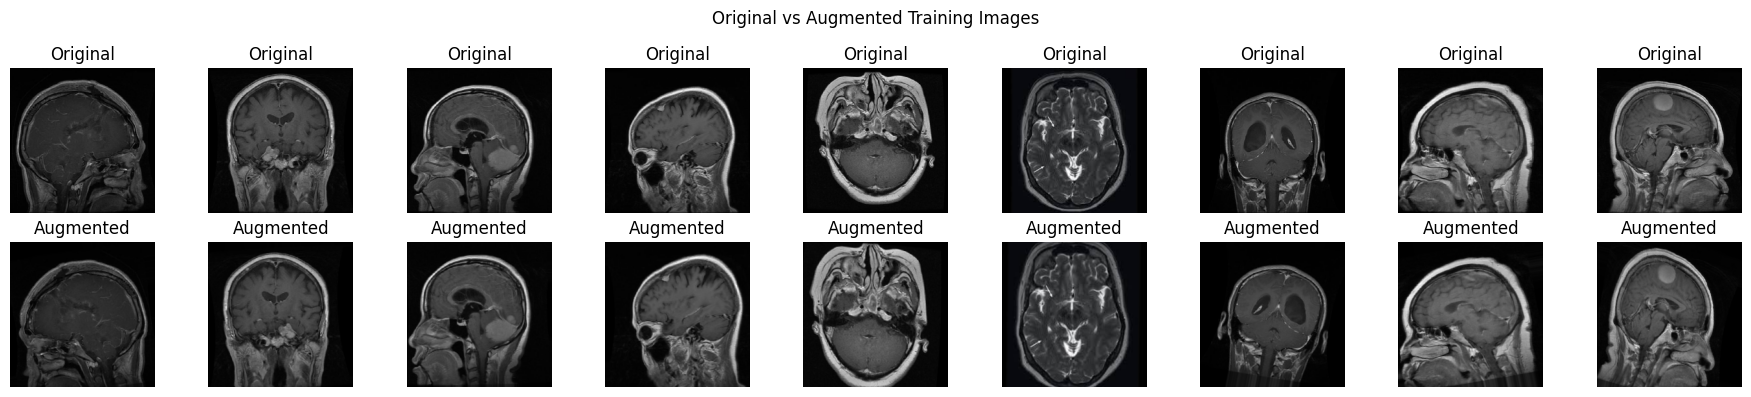

In [ ]:
# ============================================================
# VISUALISE ORIGINAL vs AUGMENTED IMAGES
# ============================================================

orig_datagen = keras.preprocessing.image.ImageDataGenerator(rescale=1./255)

orig_generator = orig_datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=9,
    class_mode='categorical',
    shuffle=True,
    seed=SEED
)

x_orig, y_orig = next(orig_generator)

# Augmented versions of the same images
x_aug = np.zeros_like(x_orig)
for i in range(x_orig.shape[0]):
    x_aug[i] = train_datagen.random_transform(x_orig[i])

fig, axes = plt.subplots(2, 9, figsize=(18, 4))
for i in range(9):
    axes[0, i].imshow(x_orig[i])
    axes[0, i].axis('off')
    axes[0, i].set_title("Original")

    axes[1, i].imshow(x_aug[i])
    axes[1, i].axis('off')
    axes[1, i].set_title("Augmented")

plt.suptitle("Original vs Augmented Training Images")
plt.tight_layout()
plt.show()


In [ ]:
# ============================================================
# HELPER: LEARNING CURVES & CONFUSION MATRIX PLOTS
# ============================================================

def plot_learning_curves(history, title_prefix="Model"):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    epochs = range(1, len(acc) + 1)

    plt.figure(figsize=(12,4))

    plt.subplot(1,2,1)
    plt.plot(epochs, acc, 'o-', label='Training acc')
    plt.plot(epochs, val_acc, 'o-', label='Validation acc')
    plt.title(f'{title_prefix} Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()

    plt.subplot(1,2,2)
    plt.plot(epochs, loss, 'o-', label='Training loss')
    plt.plot(epochs, val_loss, 'o-', label='Validation loss')
    plt.title(f'{title_prefix} Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()

    plt.tight_layout()
    plt.show()


def plot_confusion_matrix(cm, classes,
                          title='Confusion Matrix',
                          normalize=False):
    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

    plt.figure(figsize=(6,6))
    plt.imshow(cm, interpolation='nearest')
    plt.title(title)
    plt.colorbar()
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=45)
    plt.yticks(tick_marks, classes)

    fmt = '.2f' if normalize else 'd'
    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, format(cm[i, j], fmt),
                 horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black")

    plt.ylabel('True label')
    plt.xlabel('Predicted label')
    plt.tight_layout()
    plt.show()


/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_14 (Conv2D)              │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,169,476 (42.61 MB)

 Trainable params: 11,169,476 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 79s 541ms/step - accuracy: 0.5034 - loss: 1.1005 - val_accuracy: 0.6620 - val_loss: 0.7387
Epoch 2/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 70s 503ms/step - accuracy: 0.7253 - loss: 0.6658 - val_accuracy: 0.7443 - val_loss: 0.5964
Epoch 3/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 69s 498ms/step - accuracy: 0.7533 - loss: 0.5927 - val_accuracy: 0.7426 - val_loss: 0.5258
Epoch 4/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 71s 508ms/step - accuracy: 0.7913 - loss: 0.5202 - val_accuracy: 0.7548 - val_loss: 0.5085
Epoch 5/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 70s 503ms/step - accuracy: 0.8136 - loss: 0.4825 - val_accuracy: 0.7653 - val_loss: 0.5669
Epoch 6/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 69s 499ms/step - accuracy: 0.8383 - loss: 0.4279 - val_accuracy: 0.7706 - val_loss: 0.5340
Epoch 7/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 70s 501ms/step - accuracy: 0.8562 - loss: 0.3842 - val_accuracy: 0.7793 - val_loss: 0.5631
Epoch 8/10
139/139 ━━━━━━━━━━━━━━━━━━━━ 71s 508ms/step - accuracy: 0.8551 - loss: 0

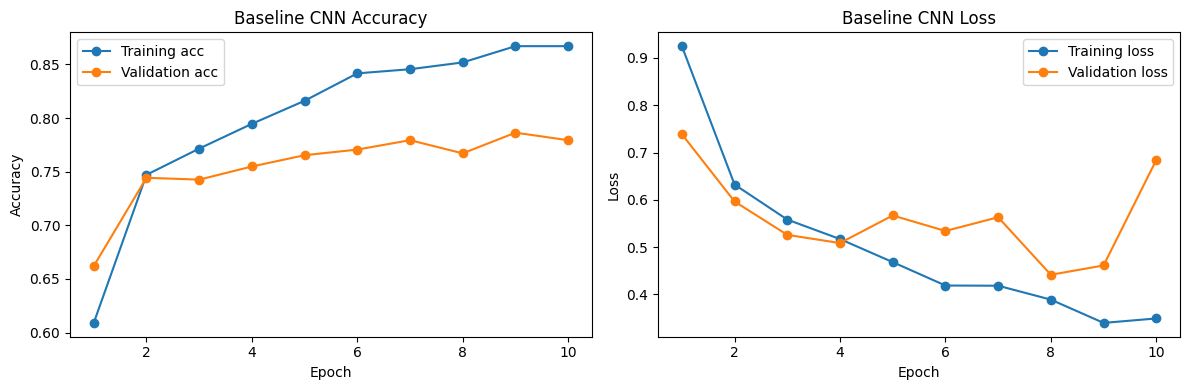

18/18 ━━━━━━━━━━━━━━━━━━━━ 2s 134ms/step - accuracy: 0.7623 - loss: 0.5635
Baseline CNN - Test loss: 0.4665, Test accuracy: 0.7986
18/18 ━━━━━━━━━━━━━━━━━━━━ 3s 154ms/step

Baseline CNN Classification Report:
              precision    recall  f1-score   support

      glioma       0.92      0.84      0.88       144
  meningioma       0.69      0.52      0.59       144
     notumor       0.69      0.83      0.75       144
   pituitary       0.89      1.00      0.94       144

    accuracy                           0.80       576
   macro avg       0.80      0.80      0.79       576
weighted avg       0.80      0.80      0.79       576



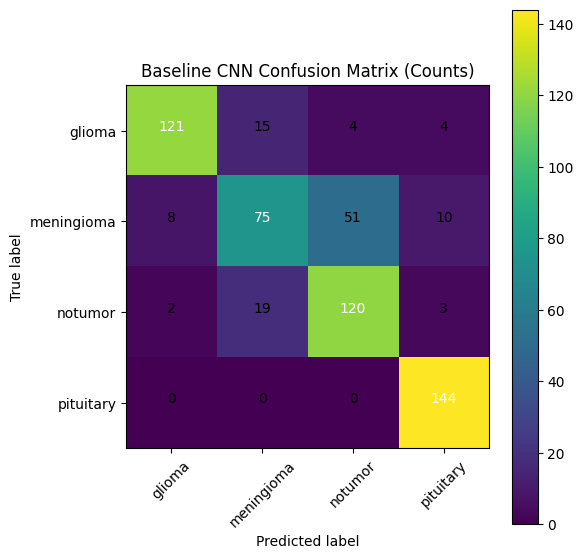

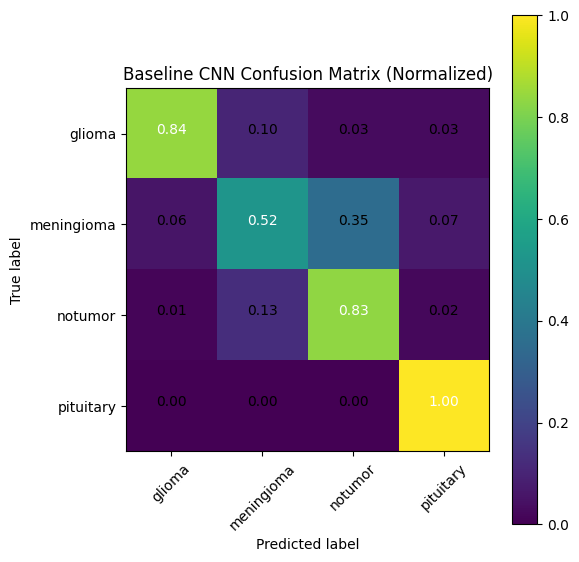

In [ ]:
# ============================================================
# MODEL 1: BASELINE CNN (Sequential)
# ============================================================

def build_baseline_cnn(input_shape=(224, 224, 3), num_classes=4):
    model = models.Sequential([
        layers.Conv2D(32, (3,3), activation='relu', input_shape=input_shape),
        layers.MaxPooling2D((2,2)),

        layers.Conv2D(64, (3,3), activation='relu'),
        layers.MaxPooling2D((2,2)),

        layers.Conv2D(128, (3,3), activation='relu'),
        layers.MaxPooling2D((2,2)),

        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(num_classes, activation='softmax')
    ])

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

baseline_model = build_baseline_cnn(
    input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3),
    num_classes=num_classes
)
baseline_model.summary()

EPOCHS_BASELINE = 10

baseline_history = baseline_model.fit(
    train_generator,
    epochs=EPOCHS_BASELINE,
    validation_data=val_generator
)

plot_learning_curves(baseline_history, title_prefix="Baseline CNN")

test_generator.reset()
base_test_loss, base_test_acc = baseline_model.evaluate(test_generator)
print(f"Baseline CNN - Test loss: {base_test_loss:.4f}, Test accuracy: {base_test_acc:.4f}")

test_generator.reset()
y_prob_base = baseline_model.predict(test_generator)
y_pred_base = np.argmax(y_prob_base, axis=1)
y_true = test_generator.classes
class_labels = list(test_generator.class_indices.keys())

print("\nBaseline CNN Classification Report:")
print(classification_report(y_true, y_pred_base, target_names=class_labels))

cm_base = confusion_matrix(y_true, y_pred_base)
plot_confusion_matrix(cm_base, classes=class_labels,
                      title='Baseline CNN Confusion Matrix (Counts)')
plot_confusion_matrix(cm_base, classes=class_labels,
                      title='Baseline CNN Confusion Matrix (Normalized)',
                      normalize=True)


In [ ]:
# ============================================================
# CONV BLOCk For Deeper Model
# ============================================================

def conv_block(x, filters):
    x = layers.Conv2D(filters, (3,3), padding='same',
                      activation='relu',
                      kernel_regularizer=regularizers.l2(1e-4))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Conv2D(filters, (3,3), padding='same',
                      activation='relu',
                      kernel_regularizer=regularizers.l2(1e-4))(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D((2,2))(x)
    x = layers.Dropout(0.25)(x)
    return x


Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_18 (Conv2D)              │ (None, 224, 224, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_19 (Conv2D)              │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_20 (Conv2D)              │ (None, 112, 112, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_21 (Conv2D)              │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_22 (Conv2D)              │ (None, 56, 56, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_16 (MaxPooling2D) │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 100352)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 256)            │    25,690,368 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 256)            │             

 Total params: 25,980,196 (99.11 MB)

 Trainable params: 25,979,300 (99.10 MB)

 Non-trainable params: 896 (3.50 KB)

Class weights: {0: 1.0, 1: 1.5, 2: 1.3, 3: 1.0}
Epoch 1/20
139/139 ━━━━━━━━━━━━━━━━━━━━ 98s 623ms/step - accuracy: 0.4880 - loss: 5.0923 - val_accuracy: 0.2522 - val_loss: 12.8733 - learning_rate: 1.0000e-04
Epoch 2/20
139/139 ━━━━━━━━━━━━━━━━━━━━ 81s 582ms/step - accuracy: 0.6863 - loss: 1.0308 - val_accuracy: 0.2522 - val_loss: 13.5446 - learning_rate: 1.0000e-04
Epoch 3/20
139/139 ━━━━━━━━━━━━━━━━━━━━ 75s 540ms/step - accuracy: 0.7074 - loss: 0.9726 - val_accuracy: 0.3905 - val_loss: 2.9050 - learning_rate: 1.0000e-04
Epoch 4/20
139/139 ━━━━━━━━━━━━━━━━━━━━ 84s 598ms/step - accuracy: 0.7530 - loss: 0.8583 - val_accuracy: 0.6322 - val_loss: 1.9996 - learning_rate: 1.0000e-04
Epoch 5/20
139/139 ━━━━━━━━━━━━━━━━━━━━ 83s 597ms/step - accuracy: 0.7454 - loss: 0.8422 - val_accuracy: 0.6778 - val_loss: 1.4687 - learning_rate: 1.0000e-04
Epoch 6/20
139/139 ━━━━━━━━━━━━━━━━━━━━ 83s 597ms/step - accuracy: 0.7559 - loss: 0.8141 - val_accuracy: 0.7180 - val_loss: 0.9287 - learning_rate: 1.0000e

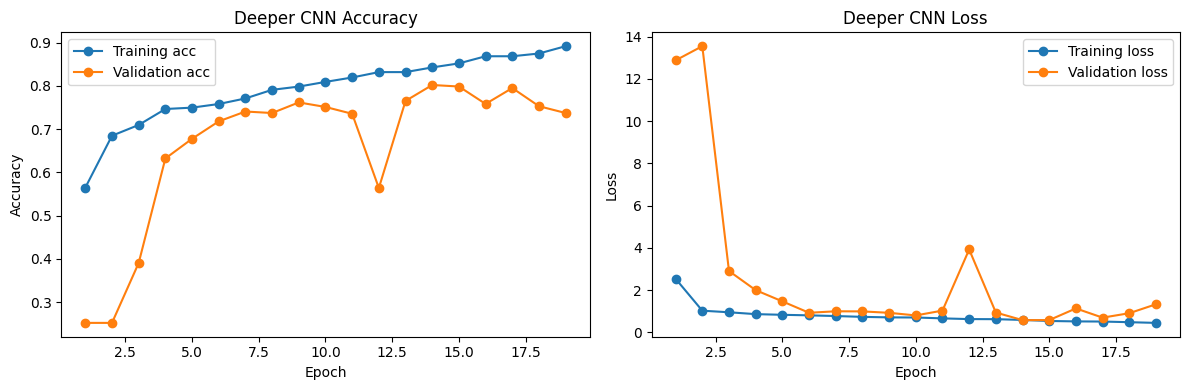

18/18 ━━━━━━━━━━━━━━━━━━━━ 5s 160ms/step - accuracy: 0.8132 - loss: 0.5788
Deeper CNN - Test loss: 0.6187, Test accuracy: 0.8247
18/18 ━━━━━━━━━━━━━━━━━━━━ 3s 127ms/step

Deeper CNN Classification Report:
              precision    recall  f1-score   support

      glioma       0.91      0.92      0.92       144
  meningioma       0.76      0.53      0.62       144
     notumor       0.72      0.92      0.81       144
   pituitary       0.91      0.92      0.92       144

    accuracy                           0.82       576
   macro avg       0.83      0.82      0.82       576
weighted avg       0.83      0.82      0.82       576



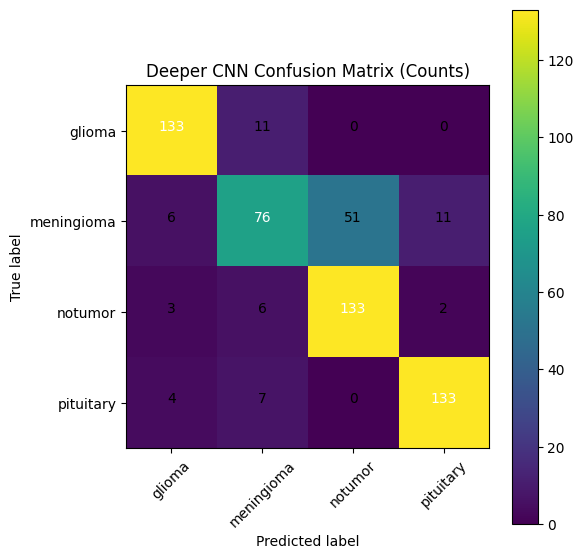

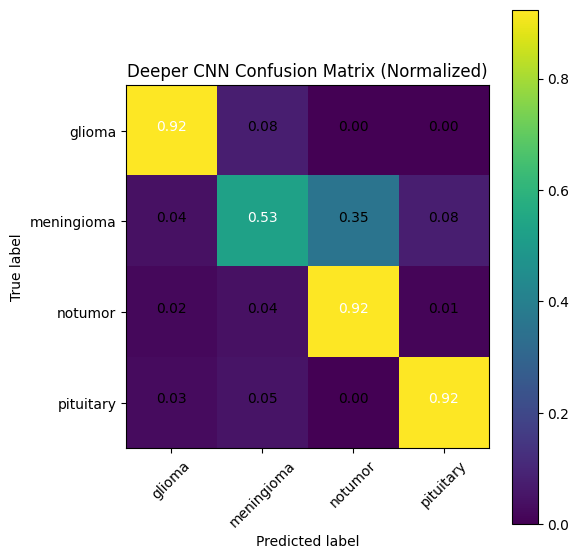

In [ ]:
# ============================================================
# MODEL 2: DEEPER CNN (Flatten head)
# ============================================================

def build_deeper_cnn(input_shape=(224, 224, 3), num_classes=4):
    inputs = keras.Input(shape=input_shape)

    x = conv_block(inputs, 32)
    x = conv_block(x, 64)
    x = conv_block(x, 128)

    x = layers.Flatten()(x)
    x = layers.Dense(256, activation='relu',
                     kernel_regularizer=regularizers.l2(1e-4))(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)

    model = keras.Model(inputs, outputs)
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-4),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

deeper_model = build_deeper_cnn(
    input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3),
    num_classes=num_classes
)
deeper_model.summary()

# Callbacks
MODEL_DIR = "/content/drive/MyDrive/brain_tumor_project"
os.makedirs(MODEL_DIR, exist_ok=True)

checkpoint_deep = keras.callbacks.ModelCheckpoint(
    os.path.join(MODEL_DIR, "best_deeper_cnn1.keras"),
    save_best_only=True,
    monitor='val_loss',
    mode='min'
)

earlystop_deep = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

reduce_lr_deep = keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

# Class weights (adjust if you like)
class_weight = {
    class_indices['glioma']:    1.0,
    class_indices['meningioma']:1.5,
    class_indices['notumor']:   1.3,
    class_indices['pituitary']: 1.0
}
print("Class weights:", class_weight)

EPOCHS_DEEP = 20

deeper_history = deeper_model.fit(
    train_generator,
    epochs=EPOCHS_DEEP,
    validation_data=val_generator,
    callbacks=[checkpoint_deep, earlystop_deep, reduce_lr_deep],
    class_weight=class_weight
)

plot_learning_curves(deeper_history, title_prefix="Deeper CNN")

# Evaluate best saved deeper model
best_deep = keras.models.load_model(os.path.join(MODEL_DIR, "best_deeper_cnn1.keras"))

test_generator.reset()
deep_test_loss, deep_test_acc = best_deep.evaluate(test_generator)
print(f"Deeper CNN - Test loss: {deep_test_loss:.4f}, Test accuracy: {deep_test_acc:.4f}")

test_generator.reset()
y_prob_deep = best_deep.predict(test_generator)
y_pred_deep = np.argmax(y_prob_deep, axis=1)
y_true = test_generator.classes

print("\nDeeper CNN Classification Report:")
print(classification_report(y_true, y_pred_deep, target_names=class_labels))

cm_deep = confusion_matrix(y_true, y_pred_deep)
plot_confusion_matrix(cm_deep, classes=class_labels,
                      title='Deeper CNN Confusion Matrix (Counts)')
plot_confusion_matrix(cm_deep, classes=class_labels,
                      title='Deeper CNN Confusion Matrix (Normalized)',
                      normalize=True)


Model: "functional_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_7 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_33 (Conv2D)              │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_27 (MaxPooling2D) │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_34 (Conv2D)              │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_28 (MaxPooling2D) │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_35 (Conv2D)              │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_29 (MaxPooling2D) │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_36 (Conv2D)              │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_30 (MaxPooling2D) │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_37 (Conv2D)              │ (None, 14, 14, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_31 (MaxPooling2D) │ (None, 7, 7, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_7 (Flatten)             │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 256)            │     3,211,520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_13 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,191,044 (15.99 MB)

 Trainable params: 4,191,044 (15.99 MB)

 Non-trainable params: 0 (0.00 B)

Class weights: {0: 1.0, 1: 1.5, 2: 1.3, 3: 1.0}
Epoch 1/25
139/139 ━━━━━━━━━━━━━━━━━━━━ 80s 541ms/step - accuracy: 0.3730 - loss: 1.4458 - val_accuracy: 0.6883 - val_loss: 0.7101 - learning_rate: 1.0000e-04
Epoch 2/25
139/139 ━━━━━━━━━━━━━━━━━━━━ 72s 518ms/step - accuracy: 0.6561 - loss: 0.9683 - val_accuracy: 0.7128 - val_loss: 0.6967 - learning_rate: 1.0000e-04
Epoch 3/25
139/139 ━━━━━━━━━━━━━━━━━━━━ 73s 524ms/step - accuracy: 0.7247 - loss: 0.8291 - val_accuracy: 0.7163 - val_loss: 0.6806 - learning_rate: 1.0000e-04
Epoch 4/25
139/139 ━━━━━━━━━━━━━━━━━━━━ 73s 525ms/step - accuracy: 0.7473 - loss: 0.7376 - val_accuracy: 0.7461 - val_loss: 0.7361 - learning_rate: 1.0000e-04
Epoch 5/25
139/139 ━━━━━━━━━━━━━━━━━━━━ 71s 508ms/step - accuracy: 0.7730 - loss: 0.6917 - val_accuracy: 0.7548 - val_loss: 0.5912 - learning_rate: 1.0000e-04
Epoch 6/25
139/139 ━━━━━━━━━━━━━━━━━━━━ 72s 516ms/step - accuracy: 0.7986 - loss: 0.6403 - val_accuracy: 0.7741 - val_loss: 0.6988 - learning_rate: 1.0000e-0

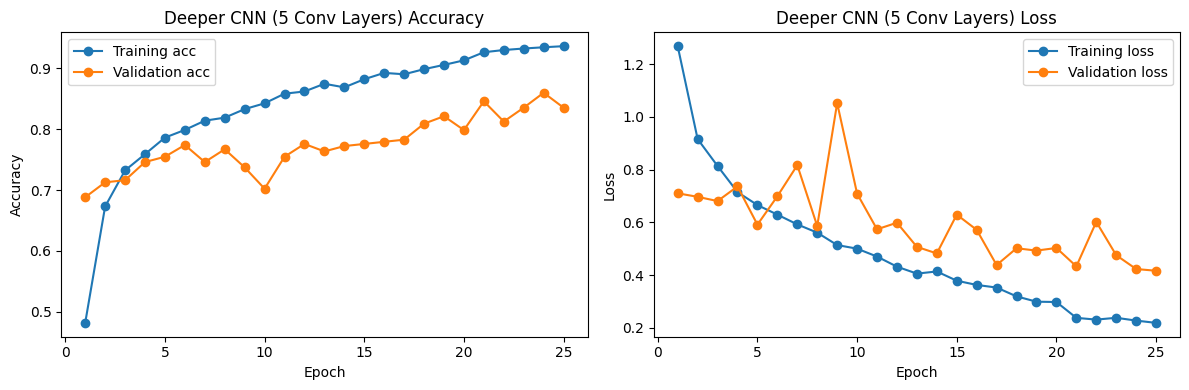

18/18 ━━━━━━━━━━━━━━━━━━━━ 4s 158ms/step - accuracy: 0.8546 - loss: 0.4212
Deeper CNN (5 Conv) - Test loss: 0.3781, Test accuracy: 0.8733
18/18 ━━━━━━━━━━━━━━━━━━━━ 3s 125ms/step

Deeper CNN (5 Conv) Classification Report:
              precision    recall  f1-score   support

      glioma       0.95      0.89      0.92       144
  meningioma       0.85      0.72      0.78       144
     notumor       0.75      0.96      0.84       144
   pituitary       0.98      0.93      0.95       144

    accuracy                           0.87       576
   macro avg       0.88      0.87      0.87       576
weighted avg       0.88      0.87      0.87       576



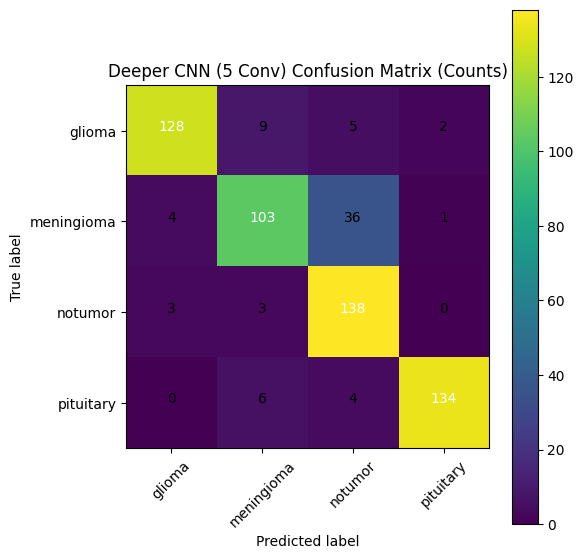

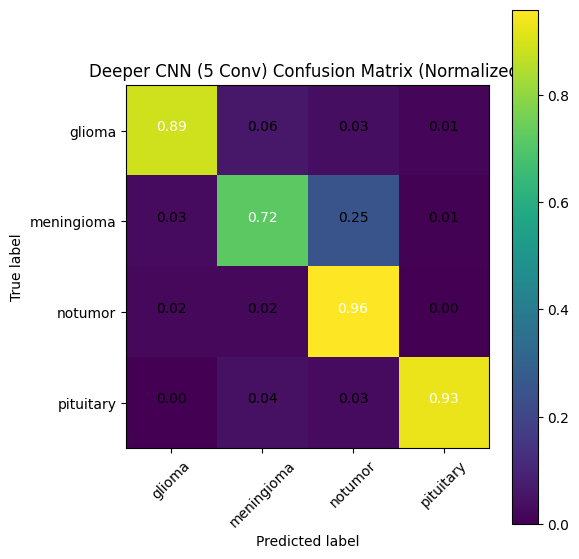

In [ ]:
# ============================================================
# MODEL 3: DEEPER CNN (5 Conv Layers)
# ============================================================

def build_deeper_cnn_5conv(input_shape=(224, 224, 3), num_classes=4):
    inputs = keras.Input(shape=input_shape)

    # Conv layer 1
    x = layers.Conv2D(32, (3, 3), activation='relu', padding='same')(inputs)
    x = layers.MaxPooling2D((2, 2))(x)

    # Conv layer 2
    x = layers.Conv2D(64, (3, 3), activation='relu', padding='same')(x)
    x = layers.MaxPooling2D((2, 2))(x)

    # Conv layer 3
    x = layers.Conv2D(128, (3, 3), activation='relu', padding='same')(x)
    x = layers.MaxPooling2D((2, 2))(x)

    # Conv layer 4
    x = layers.Conv2D(256, (3, 3), activation='relu', padding='same')(x)
    x = layers.MaxPooling2D((2, 2))(x)

    # Conv layer 5
    x = layers.Conv2D(256, (3, 3), activation='relu', padding='same')(x)
    x = layers.MaxPooling2D((2, 2))(x)

    x = layers.Flatten()(x)
    x = layers.Dense(256, activation='relu')(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)

    model = keras.Model(inputs, outputs)
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-4),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

# new instance name
deeper_model_5conv = build_deeper_cnn_5conv(
    input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3),
    num_classes=num_classes
)
deeper_model_5conv.summary()

MODEL_DIR = "/content/drive/MyDrive/brain_tumor_project"
os.makedirs(MODEL_DIR, exist_ok=True)

checkpoint_deep_5conv = keras.callbacks.ModelCheckpoint(
    os.path.join(MODEL_DIR, "best_deeper_cnn_5conv.keras"),
    save_best_only=True,
    monitor='val_loss',
    mode='min'
)

earlystop_deep_5conv = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

reduce_lr_deep_5conv = keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

# Class weights
class_weight = {
    class_indices['glioma']:     1.0,
    class_indices['meningioma']: 1.5,
    class_indices['notumor']:    1.3,
    class_indices['pituitary']:  1.0
}
print("Class weights:", class_weight)

EPOCHS_DEEP_5CONV = 25

deeper_history_5conv = deeper_model_5conv.fit(
    train_generator,
    epochs=EPOCHS_DEEP_5CONV,
    validation_data=val_generator,
    callbacks=[checkpoint_deep_5conv, earlystop_deep_5conv, reduce_lr_deep_5conv],
    class_weight=class_weight
)

plot_learning_curves(deeper_history_5conv, title_prefix="Deeper CNN (5 Conv Layers)")

# Evaluate best saved deeper model (5 conv)
best_deep_5conv = keras.models.load_model(
    os.path.join(MODEL_DIR, "best_deeper_cnn_5conv.keras")
)

test_generator.reset()
deep_test_loss_5conv, deep_test_acc_5conv = best_deep_5conv.evaluate(test_generator)
print(f"Deeper CNN (5 Conv) - Test loss: {deep_test_loss_5conv:.4f}, "
      f"Test accuracy: {deep_test_acc_5conv:.4f}")

test_generator.reset()
y_prob_deep_5conv = best_deep_5conv.predict(test_generator)
y_pred_deep_5conv = np.argmax(y_prob_deep_5conv, axis=1)
y_true = test_generator.classes

print("\nDeeper CNN (5 Conv) Classification Report:")
print(classification_report(y_true, y_pred_deep_5conv, target_names=class_labels))

cm_deep_5conv = confusion_matrix(y_true, y_pred_deep_5conv)
plot_confusion_matrix(
    cm_deep_5conv,
    classes=class_labels,
    title='Deeper CNN (5 Conv) Confusion Matrix (Counts)'
)
plot_confusion_matrix(
    cm_deep_5conv,
    classes=class_labels,
    title='Deeper CNN (5 Conv) Confusion Matrix (Normalized)',
    normalize=True
)

Final model saved to: /content/drive/MyDrive/brain_tumor_project/brain_tumor_final_model.h5
Example image path: /content/drive/MyDrive/brain_tumor_mris/Testing/glioma/Te-gl_0052.jpg
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step

Predicted class: glioma
Confidence: 0.9776
Suggested procedure: Consult neurosurgeon; consider biopsy, surgical resection, and adjuvant radiotherapy/chemotherapy depending on tumour grade.


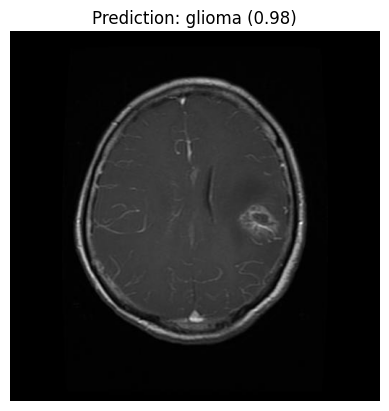

In [ ]:
# ============================================================
# 12. SAVE FINAL MODEL & SINGLE-IMAGE PREDICTION + PROCEDURE
# ============================================================

# Choose which trained model you want as "final"
final_model = best_deep_5conv

# Ensure model directory exists (TensorFlow version, no os)
tf.io.gfile.makedirs(MODEL_DIR)

final_model_path = MODEL_DIR + "/brain_tumor_final_model.h5"
final_model.save(final_model_path)
print("Final model saved to:", final_model_path)

procedure_map = {
    'glioma': (
        'Consult neurosurgeon; consider biopsy, surgical resection, '
        'and adjuvant radiotherapy/chemotherapy depending on tumour grade.'
    ),
    'meningioma': (
        'Surgical resection if accessible; regular MRI follow-up; '
        'radiotherapy for residual or inoperable cases.'
    ),
    'notumor': (
        'No tumour detected; correlate with clinical symptoms and consider '
        'further imaging or specialist review if concerns persist.'
    ),
    'pituitary': (
        'Endocrine assessment; consider transsphenoidal surgery; '
        'medical therapy or radiotherapy depending on tumour type.'
    )
}

def predict_single_image(img_path, model, class_labels, target_size=(224, 224)):
    # Use Keras utility (internally uses PIL but you don't need to touch it)
    img = image.load_img(img_path, target_size=target_size)
    img_array = image.img_to_array(img) / 255.0
    img_array = np.expand_dims(img_array, axis=0)

    preds = model.predict(img_array)[0]
    idx = np.argmax(preds)
    predicted_class = class_labels[idx]
    confidence = float(preds[idx])
    procedure = procedure_map.get(predicted_class, "Consult specialist.")

    return predicted_class, confidence, procedure

# Example: pick one image from test set (no os)
test_class_dir = test_dir + "/" + classes[0]
test_files = tf.io.gfile.listdir(test_class_dir)
example_image_path = test_class_dir + "/" + test_files[0]

print("Example image path:", example_image_path)

pred_class, conf, procedure = predict_single_image(
    example_image_path, final_model, class_labels, target_size=IMG_SIZE
)

print(f"\nPredicted class: {pred_class}")
print(f"Confidence: {conf:.4f}")
print(f"Suggested procedure: {procedure}")

# Display example image using Keras loader + matplotlib
example_img = image.load_img(example_image_path)
plt.imshow(example_img)
plt.axis('off')
plt.title(f"Prediction: {pred_class} ({conf:.2f})")
plt.show()


Number of images in notumor : 144
Chosen image: /content/drive/MyDrive/brain_tumor_mris/Testing/notumor/Te-no_0099.jpg
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 114ms/step

Predicted class: notumor
Confidence: 0.9783
Suggested procedure: No tumour detected; correlate with clinical symptoms and consider further imaging or specialist review if concerns persist.


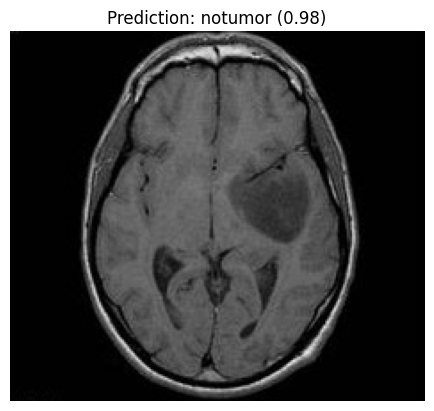

In [ ]:
# Choose class and index
test_class = "notumor"
idx = 89

# Build folder path
class_folder = test_dir + "/" + test_class

# List files in that class folder using tf.io.gfile
file_list = sorted(tf.io.gfile.listdir(class_folder))
print("Number of images in", test_class, ":", len(file_list))

# Safety check (optional but useful)
if idx >= len(file_list):
    print(f"Index {idx} is out of range for class {test_class}.")
else:
    example_image_path = class_folder + "/" + file_list[idx]
    print("Chosen image:", example_image_path)

    pred_class, conf, procedure, _ = predict_single_image(
        example_image_path, final_model, class_labels, target_size=IMG_SIZE
    )

    print(f"\nPredicted class: {pred_class}")
    print(f"Confidence: {conf:.4f}")
    print(f"Suggested procedure: {procedure}")

    # Display example image using Keras loader + matplotlib
    img = load_img(example_image_path)
    plt.imshow(img)
    plt.axis('off')
    plt.title(f"Prediction: {pred_class} ({conf:.2f})")
    plt.show()


Number of images in pituitary : 144
Chosen image: /content/drive/MyDrive/brain_tumor_mris/Testing/pituitary/Te-pi_0123.jpg
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step

Predicted class: pituitary
Confidence: 0.9662
Suggested procedure: Endocrine assessment; consider transsphenoidal surgery; medical therapy or radiotherapy depending on tumour type.


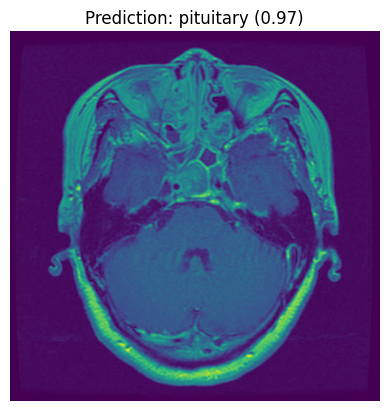

In [ ]:
# Choose class and index
test_class = "pituitary"
idx = 113

# Build folder path
class_folder = test_dir + "/" + test_class

# List files in that class folder using tf.io.gfile
file_list = sorted(tf.io.gfile.listdir(class_folder))
print("Number of images in", test_class, ":", len(file_list))

# Safety check (optional but useful)
if idx >= len(file_list):
    print(f"Index {idx} is out of range for class {test_class}.")
else:
    example_image_path = class_folder + "/" + file_list[idx]
    print("Chosen image:", example_image_path)

    pred_class, conf, procedure, _ = predict_single_image(
        example_image_path, final_model, class_labels, target_size=IMG_SIZE
    )

    print(f"\nPredicted class: {pred_class}")
    print(f"Confidence: {conf:.4f}")
    print(f"Suggested procedure: {procedure}")

    # Display example image using Keras loader + matplotlib
    img = load_img(example_image_path)
    plt.imshow(img)
    plt.axis('off')
    plt.title(f"Prediction: {pred_class} ({conf:.2f})")
    plt.show()


Number of images in meningioma : 144
Chosen image: /content/drive/MyDrive/brain_tumor_mris/Testing/meningioma/Te-me_0018.jpg
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step

Predicted class: meningioma
Confidence: 0.8939
Suggested procedure: Surgical resection if accessible; regular MRI follow-up; radiotherapy for residual or inoperable cases.


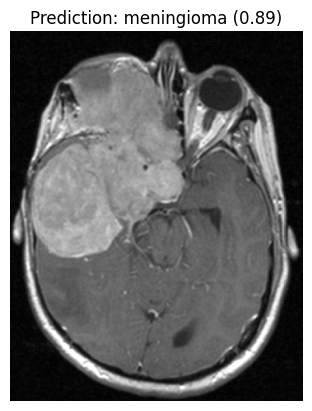

In [ ]:
# Choose class and index
test_class = "meningioma"
idx = 8

# Build folder path
class_folder = test_dir + "/" + test_class

# List files in that class folder using tf.io.gfile
file_list = sorted(tf.io.gfile.listdir(class_folder))
print("Number of images in", test_class, ":", len(file_list))

# Safety check (optional but useful)
if idx >= len(file_list):
    print(f"Index {idx} is out of range for class {test_class}.")
else:
    example_image_path = class_folder + "/" + file_list[idx]
    print("Chosen image:", example_image_path)

    pred_class, conf, procedure, _ = predict_single_image(
        example_image_path, final_model, class_labels, target_size=IMG_SIZE
    )

    print(f"\nPredicted class: {pred_class}")
    print(f"Confidence: {conf:.4f}")
    print(f"Suggested procedure: {procedure}")

    # Display example image using Keras loader + matplotlib
    img = load_img(example_image_path)
    plt.imshow(img)
    plt.axis('off')
    plt.title(f"Prediction: {pred_class} ({conf:.2f})")
    plt.show()


Number of images in glioma : 144
Chosen image: /content/drive/MyDrive/brain_tumor_mris/Testing/glioma/Te-gl_0028.jpg
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step

Predicted class: glioma
Confidence: 0.8388
Suggested procedure: Consult neurosurgeon; consider biopsy, surgical resection, and adjuvant radiotherapy/chemotherapy depending on tumour grade.


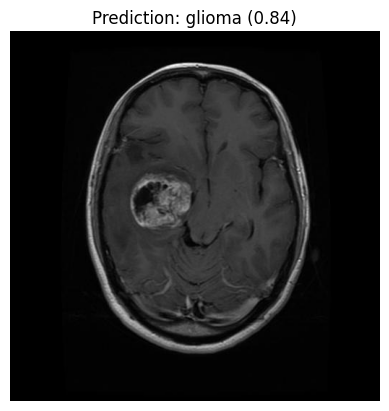

In [ ]:
# Choose class and index
test_class = "glioma"
idx = 18

# Build folder path
class_folder = test_dir + "/" + test_class

# List files in that class folder using tf.io.gfile
file_list = sorted(tf.io.gfile.listdir(class_folder))
print("Number of images in", test_class, ":", len(file_list))

# Safety check (optional but useful)
if idx >= len(file_list):
    print(f"Index {idx} is out of range for class {test_class}.")
else:
    example_image_path = class_folder + "/" + file_list[idx]
    print("Chosen image:", example_image_path)

    pred_class, conf, procedure, _ = predict_single_image(
        example_image_path, final_model, class_labels, target_size=IMG_SIZE
    )

    print(f"\nPredicted class: {pred_class}")
    print(f"Confidence: {conf:.4f}")
    print(f"Suggested procedure: {procedure}")

    # Display example image using Keras loader + matplotlib
    img = load_img(example_image_path)
    plt.imshow(img)
    plt.axis('off')
    plt.title(f"Prediction: {pred_class} ({conf:.2f})")
    plt.show()
